# Deep Learning Practical Report 6 — Opening the Transformer
**Red & White Skill Education | Deep Learning | PR 6**

This notebook inspects pretrained Transformer models; it does not train or fine-tune them. It covers tokenization, self-attention, positional encoding, normalization, encoder/decoder behaviour, inference, and a small sentiment/summary/translation toolkit.

**Models**
- `distilbert-base-uncased-finetuned-sst-2-english` — sentiment classification
- `distilbert-base-uncased` — encoder attention and fill-mask
- `gpt2` — causal decoder and generation
- `t5-small` — encoder-decoder translation and summarization

Run from top to bottom. The first run downloads public models and the IMDB sample, so an internet connection is required. CPU execution is supported; some timing values will vary by machine.

## Setup and reproducibility
Objective: import libraries and set deterministic seeds. Expected output: package imports and seed configuration.

In [71]:
# Run this cell to complete the current practical step.
import os, time, math, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from datasets import load_dataset
from transformers import (
    pipeline, AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
    AutoModelForMaskedLM, AutoModelForCausalLM, T5Tokenizer,
    T5ForConditionalGeneration
)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else -1
TORCH_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(exist_ok=True)
print("PyTorch:", torch.__version__)
print("Device:", TORCH_DEVICE)

PyTorch: 2.6.0+cu124
Device: cuda


## Task 1 — Introduction, history, pipelines and tokenizer
Objective: run a pretrained sentiment pipeline and inspect tokenization/model anatomy. Expected output: labels, token IDs, masks, configuration and parameter counts.

In [72]:
# Run this cell to complete the current practical step.
sentiment_model_id = "distilbert-base-uncased-finetuned-sst-2-english"
sentiment_pipe = pipeline("sentiment-analysis", model=sentiment_model_id, device=DEVICE)
sentences = [
    "This film was wonderful and beautifully acted.",
    "I disliked nearly every minute of this movie.",
    "I expected it to be bad, but it was surprisingly good.",
    "The plot was not terrible, although the ending was weak.",
    "The acting is excellent and I would recommend it."
]
for sentence, result in zip(sentences, sentiment_pipe(sentences)):
    print(f"{sentence}\n  {result['label']} ({result['score']:.4f})")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 21773.37it/s]


This film was wonderful and beautifully acted.
  POSITIVE (0.9999)
I disliked nearly every minute of this movie.
  NEGATIVE (0.9994)
I expected it to be bad, but it was surprisingly good.
  POSITIVE (0.9998)
The plot was not terrible, although the ending was weak.
  NEGATIVE (0.9917)
The acting is excellent and I would recommend it.
  POSITIVE (0.9999)


### Transformer timeline
| Year | Model/paper | Why it mattered |
|---|---|---|
| 2014–2015 | Seq2seq with Bahdanau/Luong attention | Let a decoder focus on relevant encoder states instead of relying on one fixed context vector. |
| 2017 | *Attention Is All You Need* | Introduced the Transformer architecture built around attention and parallel sequence processing. |
| 2018 | BERT and GPT | Popularized pretrained bidirectional encoders and autoregressive decoder language models. |
| 2019 | GPT-2, T5, DistilBERT | Demonstrated stronger text generation, a text-to-text framework, and a smaller distilled encoder. |
| 2020 onward | Large language models and Vision Transformers | Extended Transformer scaling to broad language tasks and image patches. |

RNNs/LSTMs process tokens sequentially, which limits parallelism and can make long-range dependencies difficult to preserve. Transformer self-attention lets tokens directly compare with other tokens in a layer, allowing parallel processing during training and flexible long-range interactions.

### Impact and disadvantages

**Impact:** translation, semantic search, chat assistants, code completion, image understanding/generation, and protein-structure prediction.

**Disadvantages:** attention cost can grow roughly quadratically with sequence length; context windows are limited; models can require substantial compute and memory; pretraining needs large datasets; generated answers can hallucinate; and internal decisions are difficult to interpret.

In [73]:
# Run this cell to complete the current practical step.
tok = AutoTokenizer.from_pretrained(sentiment_model_id)
text = "Transformers are surprisingly easy to understand."
encoded = tok(text)
print("Tokens:", tok.tokenize(text))
print("input_ids:", encoded["input_ids"])
print("attention_mask:", encoded["attention_mask"])
print("Decoded:", tok.convert_ids_to_tokens(encoded["input_ids"]))
long_word = "antidisestablishmentarianism"
print("Subword split:", tok.tokenize(long_word))
print("Special tokens:", tok.special_tokens_map)

Tokens: ['transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.']
input_ids: [101, 19081, 2024, 10889, 3733, 2000, 3305, 1012, 102]
attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1]
Decoded: ['[CLS]', 'transformers', 'are', 'surprisingly', 'easy', 'to', 'understand', '.', '[SEP]']
Subword split: ['anti', '##dis', '##est', '##ab', '##lish', '##ment', '##arian', '##ism']
Special tokens: {'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}


In [74]:
# Run this cell to complete the current practical step.
batch = tok(
    ["Transformers process tokens.", "Attention lets models connect distant words in a sentence."],
    padding=True, return_tensors="pt"
)
print("input_ids:\n", batch["input_ids"])
print("attention_mask:\n", batch["attention_mask"])

input_ids:
 tensor([[  101, 19081,  2832, 19204,  2015,  1012,   102,     0,     0,     0,
             0,     0],
        [  101,  3086, 11082,  4275,  7532,  6802,  2616,  1999,  1037,  6251,
          1012,   102]])
attention_mask:
 tensor([[1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]])


In [75]:
# Run this cell to complete the current practical step.
clf_model = AutoModelForSequenceClassification.from_pretrained(sentiment_model_id)
cfg = clf_model.config
anatomy = pd.DataFrame({
    "Property": ["Layers", "Attention heads", "Hidden size", "Vocabulary size", "Maximum positions", "Total parameters"],
    "Value": [getattr(cfg, "n_layers", getattr(cfg, "num_hidden_layers", "see config")),
              getattr(cfg, "n_heads", getattr(cfg, "num_attention_heads", "see config")),
              cfg.hidden_size, cfg.vocab_size, cfg.max_position_embeddings,
              sum(p.numel() for p in clf_model.parameters())]
})
display(anatomy)
print("First 15 parameter names:")
for name, _ in list(clf_model.named_parameters())[:15]:
    print(name)

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 2071.61it/s]


,Property,Value
0,Layers,6
1,Attention heads,12
2,Hidden size,768
3,Vocabulary size,30522
4,Maximum positions,512
5,Total parameters,66955010


First 15 parameter names:
distilbert.embeddings.word_embeddings.weight
distilbert.embeddings.position_embeddings.weight
distilbert.embeddings.LayerNorm.weight
distilbert.embeddings.LayerNorm.bias
distilbert.transformer.layer.0.attention.q_lin.weight
distilbert.transformer.layer.0.attention.q_lin.bias
distilbert.transformer.layer.0.attention.k_lin.weight
distilbert.transformer.layer.0.attention.k_lin.bias
distilbert.transformer.layer.0.attention.v_lin.weight
distilbert.transformer.layer.0.attention.v_lin.bias
distilbert.transformer.layer.0.attention.out_lin.weight
distilbert.transformer.layer.0.attention.out_lin.bias
distilbert.transformer.layer.0.sa_layer_norm.weight
distilbert.transformer.layer.0.sa_layer_norm.bias
distilbert.transformer.layer.0.ffn.lin1.weight


## Task 2 — Self-attention and scaled dot-product attention
Objective: implement attention from scratch, compare scaling choices and Luong attention, demonstrate order-blindness, and verify a real attention head.

X, Q, K, V: (4, 8) (4, 8) (4, 8) (4, 8)
scores, weights, output: (4, 4) (4, 4) (4, 8)
Row sums: [1. 1. 1. 1.]


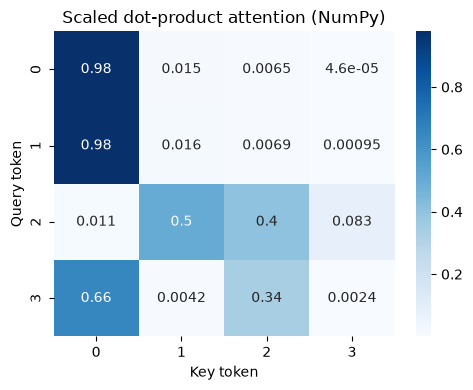

In [76]:
# Run this cell to complete the current practical step.
def softmax_stable(x, axis=-1):
    x = np.asarray(x, dtype=np.float64)
    x_shifted = x - np.max(x, axis=axis, keepdims=True)
    exp_x = np.exp(x_shifted)
    return exp_x / exp_x.sum(axis=axis, keepdims=True)

rng = np.random.default_rng(SEED)
X = rng.normal(size=(4, 8))
Wq, Wk, Wv = [rng.normal(size=(8, 8)) for _ in range(3)]
Q, K, V = X @ Wq, X @ Wk, X @ Wv
scores = Q @ K.T / np.sqrt(Q.shape[-1])
weights = softmax_stable(scores, axis=-1)
attn_output = weights @ V
print("X, Q, K, V:", X.shape, Q.shape, K.shape, V.shape)
print("scores, weights, output:", scores.shape, weights.shape, attn_output.shape)
print("Row sums:", weights.sum(axis=1))
plt.figure(figsize=(5, 4))
sns.heatmap(weights, annot=True, cmap="Blues")
plt.title("Scaled dot-product attention (NumPy)")
plt.xlabel("Key token")
plt.ylabel("Query token")
plt.tight_layout()
plt.savefig(PLOT_DIR / "attention_scratch.png", dpi=150)
plt.show()

In [77]:
# Run this cell to complete the current practical step.
rng = np.random.default_rng(SEED)
for dk in [4, 256]:
    q = rng.normal(size=(32, dk))
    k = rng.normal(size=(32, dk))
    raw = q @ k.T
    for scaled in [False, True]:
        s = raw / np.sqrt(dk) if scaled else raw
        p = softmax_stable(s, axis=-1)
        entropy = -(p * np.log(p + 1e-12)).sum(axis=1).mean()
        print(f"d_k={dk:3d}, scaled={scaled}: mean row max={p.max(axis=1).mean():.4f}, entropy={entropy:.4f}")

d_k=  4, scaled=False: mean row max=0.2444, entropy=2.5214
d_k=  4, scaled=True: mean row max=0.1165, entropy=3.1551
d_k=256, scaled=False: mean row max=0.8982, entropy=0.2506
d_k=256, scaled=True: mean row max=0.1673, entropy=3.0063


In [78]:
# Run this cell to complete the current practical step.
rng = np.random.default_rng(SEED)
encoder_states = rng.normal(size=(5, 8))
decoder_state = rng.normal(size=8)
luong_scores = encoder_states @ decoder_state
luong_weights = softmax_stable(luong_scores)
context = luong_weights @ encoder_states
print("Luong attention weights:", luong_weights)
print("Context shape:", context.shape)

Luong attention weights: [0.06318682 0.12474626 0.19145661 0.58760434 0.03300598]
Context shape: (8,)


| Feature | Luong dot attention | Self-attention |
|---|---|---|
| Queries | Decoder hidden state | Every token's projected state |
| Keys/values | Encoder hidden states | Same sequence's projected states |
| Attended over | Source/encoder states | All tokens in the same sequence |
| Requires an RNN | Traditionally paired with seq2seq RNNs | No |
| Parallelism | Decoder steps may be sequential | All positions can be processed in parallel |
| Common location | Encoder-decoder bridge | Transformer encoder/decoder blocks |

In [79]:
# Run this cell to complete the current practical step.
perm = np.array([2, 0, 3, 1])
X_perm = X[perm]
out_perm = softmax_stable((X_perm @ Wq) @ (X_perm @ Wk).T / np.sqrt(8)) @ (X_perm @ Wv)
print("Output rows match shuffled original:", np.allclose(out_perm, attn_output[perm], atol=1e-8))

Output rows match shuffled original: True


In [80]:
# Verify DistilBERT layer-0, head-0 attention using its q_lin/k_lin projections.
verify_tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")
verify_model = AutoModel.from_pretrained("distilbert-base-uncased", attn_implementation="eager").to(TORCH_DEVICE).eval()
verify_text = "The animal did not cross the street because it was too tired."
vinputs = verify_tok(verify_text, return_tensors="pt").to(TORCH_DEVICE)
with torch.no_grad():
    vout = verify_model(**vinputs, output_hidden_states=True, output_attentions=True)
hidden = vout.hidden_states[0]
attn_layer = verify_model.transformer.layer[0].attention
q = attn_layer.q_lin(hidden).view(1, -1, 12, 64).transpose(1, 2)
k = attn_layer.k_lin(hidden).view(1, -1, 12, 64).transpose(1, 2)
manual_scores = q @ k.transpose(-1, -2) / np.sqrt(64)
mask = vinputs["attention_mask"][:, None, None, :]
manual_scores = manual_scores.masked_fill(mask == 0, torch.finfo(manual_scores.dtype).min)
manual_attn = torch.softmax(manual_scores, dim=-1)
difference = (manual_attn[0, 0] - vout.attentions[0][0, 0]).abs().max().item()
print("Maximum absolute difference:", difference)
print(
    "Allclose at 1e-4:",
    np.allclose(
        manual_attn[0, 0].detach().cpu().numpy(),
        vout.attentions[0][0, 0].detach().cpu().numpy(),
        atol=1e-4
    )
)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1169.21it/s]
[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Maximum absolute difference: 0.0
Allclose at 1e-4: True


## Task 3 — Multi-head attention, positional encoding and normalization

Attention tensor shapes: [(1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15), (1, 12, 15, 15)]


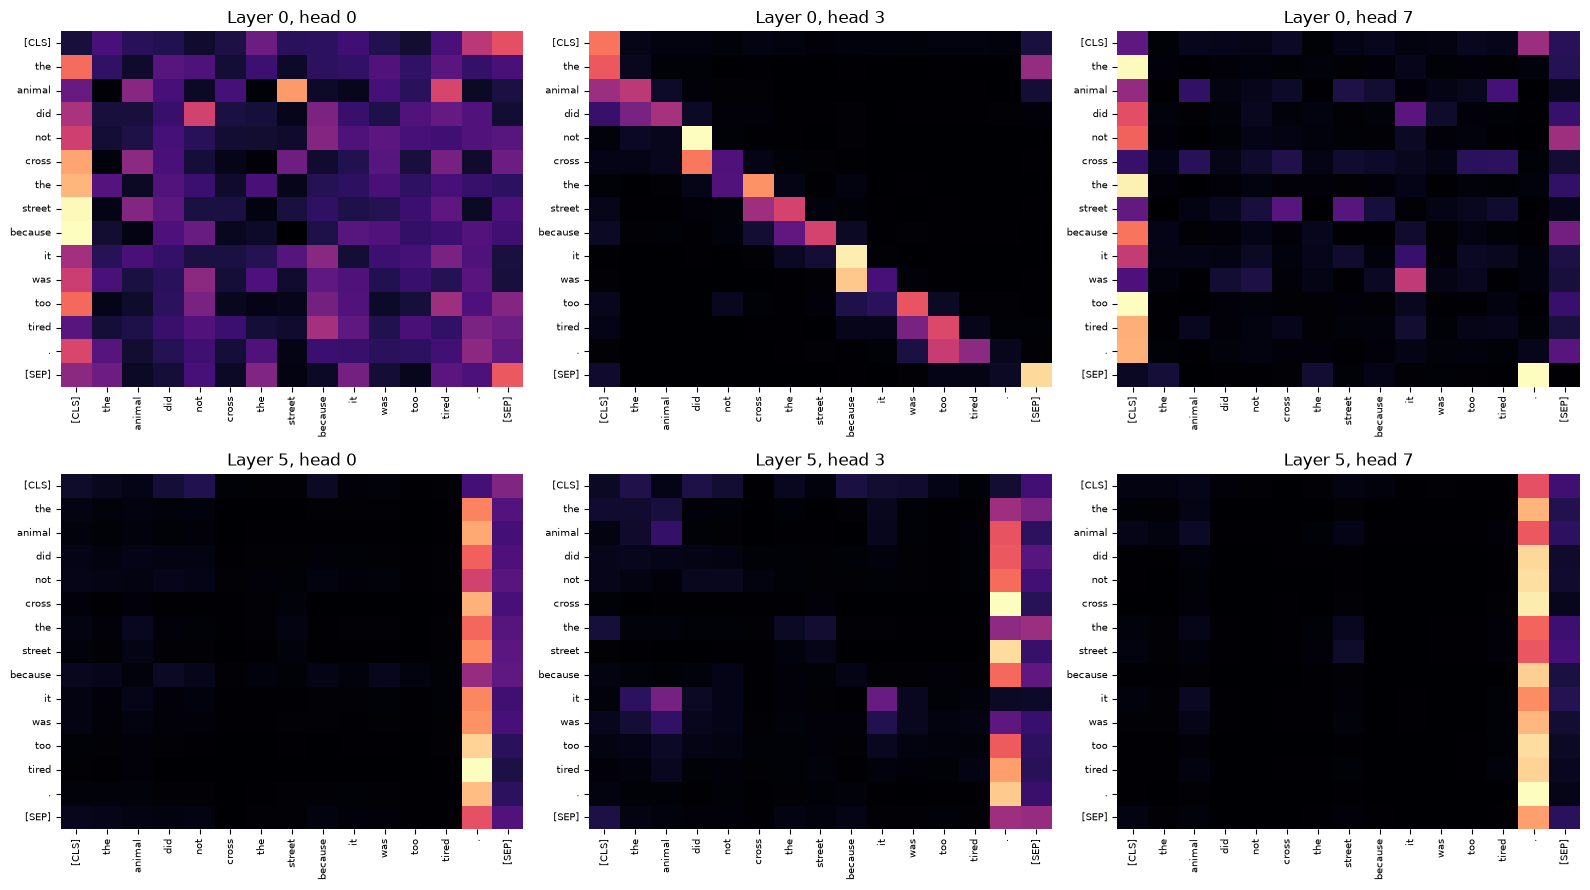

In [81]:
# Run this cell to complete the current practical step.
with torch.no_grad():
    head_out = verify_model(**vinputs, output_attentions=True)
tokens = verify_tok.convert_ids_to_tokens(vinputs["input_ids"][0])
print("Attention tensor shapes:", [tuple(a.shape) for a in head_out.attentions])
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
selected = [(0,0), (0,3), (0,7), (5,0), (5,3), (5,7)]
for ax, (layer_i, head_i) in zip(axes.flat, selected):
    arr = head_out.attentions[layer_i][0, head_i].cpu().numpy()
    sns.heatmap(arr, xticklabels=tokens, yticklabels=tokens, cmap="magma", ax=ax, cbar=False)
    ax.set_title(f"Layer {layer_i}, head {head_i}")
    ax.tick_params(axis="x", rotation=90, labelsize=7); ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(PLOT_DIR/"attention_heads.png", dpi=150); plt.show()

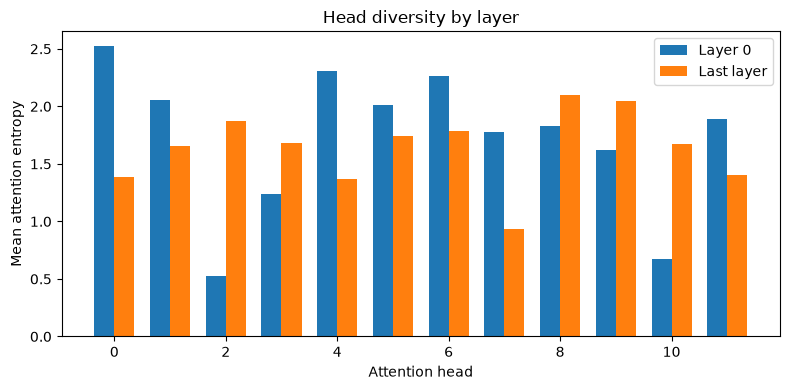

Entropy values are descriptive for this sentence only; avoid generalizing from one example.


In [82]:
# Run this cell to complete the current practical step.
def attention_entropy(att):
    p = att.detach().cpu().numpy()
    return -(p * np.log(p + 1e-12)).sum(axis=-1).mean(axis=(0, 2))
entropy_first = attention_entropy(head_out.attentions[0])
entropy_last = attention_entropy(head_out.attentions[-1])
plt.figure(figsize=(8,4))
plt.bar(np.arange(12)-0.18, entropy_first, width=0.36, label="Layer 0")
plt.bar(np.arange(12)+0.18, entropy_last, width=0.36, label="Last layer")
plt.xlabel("Attention head"); plt.ylabel("Mean attention entropy"); plt.title("Head diversity by layer"); plt.legend()
plt.tight_layout(); plt.savefig(PLOT_DIR/"head_entropy.png", dpi=150); plt.show()
print("Entropy values are descriptive for this sentence only; avoid generalizing from one example.")

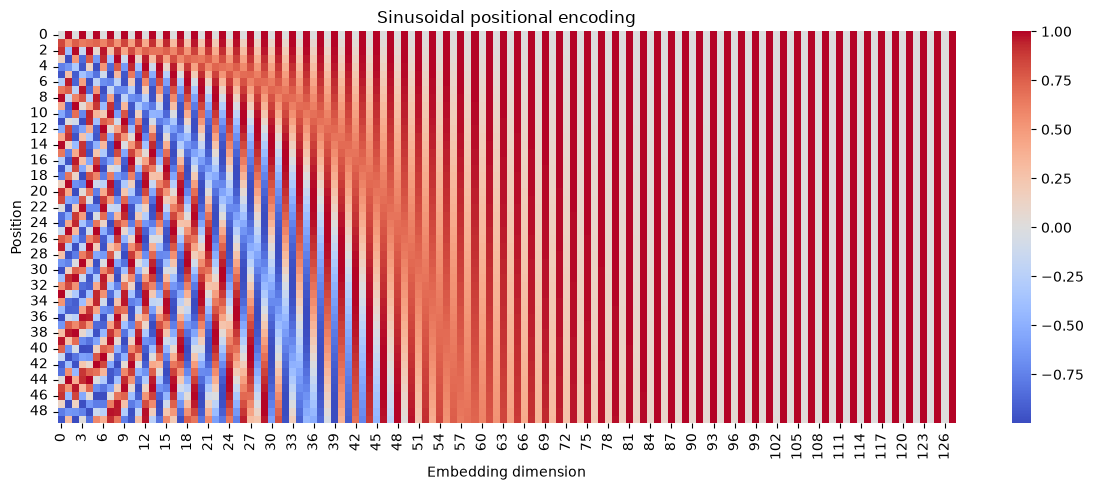

Cosine similarity without PE: 1.0
Cosine similarity with PE: 0.8260652109464316


In [83]:
# Run this cell to complete the current practical step.
positions, d_model = 50, 128
pos = np.arange(positions)[:, None]
i = np.arange(d_model)[None, :]
angles = pos / np.power(10000, (2 * (i // 2)) / d_model)
PE = np.zeros((positions, d_model))
PE[:, 0::2] = np.sin(angles[:, 0::2])
PE[:, 1::2] = np.cos(angles[:, 1::2])
plt.figure(figsize=(12, 5))
sns.heatmap(PE, cmap="coolwarm", center=0)
plt.title("Sinusoidal positional encoding")
plt.xlabel("Embedding dimension")
plt.ylabel("Position")
plt.tight_layout()
plt.savefig(PLOT_DIR / "positional_encoding.png", dpi=150)
plt.show()
word = np.random.default_rng(SEED).normal(size=d_model)
a, b = word + PE[3], word + PE[20]
cos = lambda u,v: float(np.dot(u,v)/(np.linalg.norm(u)*np.linalg.norm(v)))
print("Cosine similarity without PE:", cos(word, word))
print("Cosine similarity with PE:", cos(a, b))

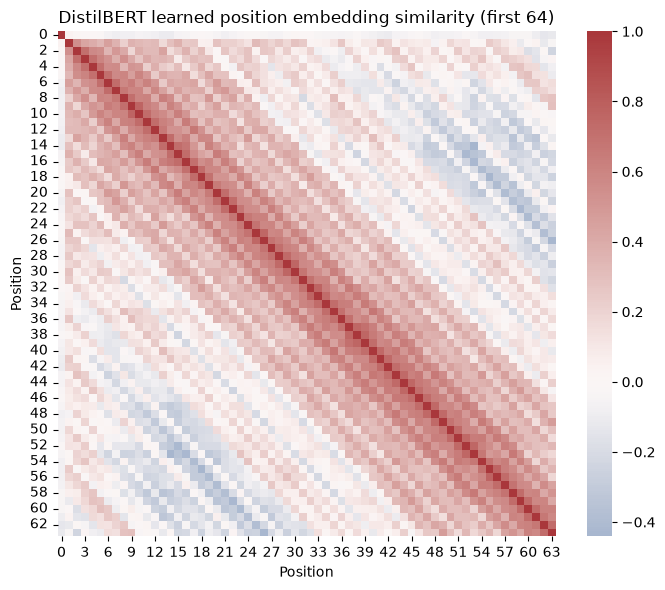

Position embedding table shape: (512, 768) (maximum position index is limited by model configuration)


In [84]:
# Run this cell to complete the current practical step.
position_weights = verify_model.embeddings.position_embeddings.weight.detach().cpu().numpy()
pos64 = position_weights[:64]
normed = pos64 / (np.linalg.norm(pos64, axis=1, keepdims=True) + 1e-12)
sim = normed @ normed.T
plt.figure(figsize=(7,6)); sns.heatmap(sim, cmap="vlag", center=0)
plt.title("DistilBERT learned position embedding similarity (first 64)")
plt.xlabel("Position")
plt.ylabel("Position")
plt.tight_layout(); plt.savefig(PLOT_DIR/"learned_position_similarity.png", dpi=150); plt.show()
print("Position embedding table shape:", position_weights.shape, "(maximum position index is limited by model configuration)")

In [85]:
# Run this cell to complete the current practical step.
rng = np.random.default_rng(SEED)
A = rng.normal(size=(4,8))
gamma, beta, eps = np.ones(8), np.zeros(8), 1e-5
layernorm_np = gamma * (A - A.mean(axis=-1, keepdims=True)) / np.sqrt(A.var(axis=-1, keepdims=True) + eps) + beta
torch_ln = torch.nn.LayerNorm(8, elementwise_affine=True)
with torch.no_grad():
    torch_ln.weight.fill_(1); torch_ln.bias.zero_()
torch_result = torch_ln(torch.tensor(A, dtype=torch.float32)).detach().cpu().numpy()
print("NumPy per-token means:", layernorm_np.mean(axis=1))
print("NumPy per-token std:", layernorm_np.std(axis=1))
print("Matches torch LayerNorm:", np.allclose(layernorm_np, torch_result, atol=1e-5))
batch_norm_like = (A - A.mean(axis=0, keepdims=True)) / np.sqrt(A.var(axis=0, keepdims=True) + eps)
print("BatchNorm-like per-token means (not necessarily 0):", batch_norm_like.mean(axis=1))
print("DistilBERT embedding LayerNorm gamma/beta shapes:",
      tuple(verify_model.embeddings.LayerNorm.weight.shape), tuple(verify_model.embeddings.LayerNorm.bias.shape))

NumPy per-token means: [ 0.00000000e+00  0.00000000e+00 -5.55111512e-17  5.55111512e-17]
NumPy per-token std: [0.99999464 0.99999006 0.99998953 0.99999188]
Matches torch LayerNorm: True
BatchNorm-like per-token means (not necessarily 0): [-0.33349847  0.08069922  0.09897601  0.15382324]
DistilBERT embedding LayerNorm gamma/beta shapes: (768,) (768,)


**LayerNorm vs BatchNorm:** LayerNorm normalizes features within each token independently and is robust to variable sequence/batch sizes. BatchNorm normalizes each feature across examples/tokens in the batch, so its statistics depend on batch composition and padding. Transformers commonly use LayerNorm because token representations and sequence lengths vary. Gamma is the learned scale; beta is the learned shift.

## Task 4 — Encoder architecture and masked self-attention

In [86]:
# Run this cell to complete the current practical step.
print(verify_model)
module_table = pd.DataFrame([
    ["Token embedding", "embeddings.word_embeddings"],
    ["Position embedding", "embeddings.position_embeddings"],
    ["Embedding LayerNorm", "embeddings.LayerNorm"],
    ["Attention projections", "transformer.layer[0].attention.q_lin / k_lin / v_lin / out_lin"],
    ["Feed-forward", "transformer.layer[0].ffn.lin1 / lin2 / activation"],
    ["Block LayerNorms", "transformer.layer[0].sa_layer_norm / output_layer_norm"]
], columns=["Component", "Module name"])
display(module_table)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

,Component,Module name
0,Token embedding,embeddings.word_embeddings
1,Position embedding,embeddings.position_embeddings
2,Embedding LayerNorm,embeddings.LayerNorm
3,Attention projections,transformer.layer[0].attention.q_lin / k_lin /...
4,Feed-forward,transformer.layer[0].ffn.lin1 / lin2 / activation
5,Block LayerNorms,transformer.layer[0].sa_layer_norm / output_la...


,Component,Parameters,Share (%)
0,embeddings,23835648,35.599499
1,attention,14174208,21.169750
2,feed-forward,28334592,42.318853
3,layer norms,18432,0.027529
4,classification head,592130,0.884370
5,other,0,0.000000


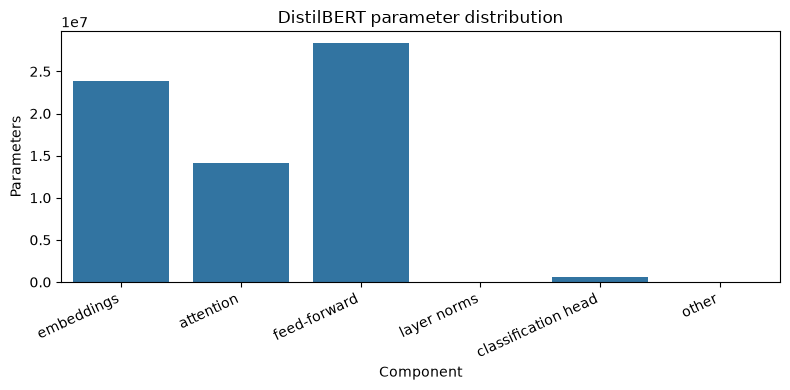

In [87]:
# Run this cell to complete the current practical step.
groups = {"embeddings":0, "attention":0, "feed-forward":0, "layer norms":0, "classification head":0, "other":0}
for name, p in clf_model.named_parameters():
    n = p.numel()
    if "embeddings" in name: key = "embeddings"
    elif any(x in name for x in ["q_lin","k_lin","v_lin","out_lin"]): key = "attention"
    elif any(x in name for x in ["ffn","lin1","lin2"]): key = "feed-forward"
    elif "LayerNorm" in name or "layer_norm" in name: key = "layer norms"
    elif "pre_classifier" in name or "classifier" in name: key = "classification head"
    else: key = "other"
    groups[key] += n
param_df = pd.DataFrame({"Component": list(groups.keys()), "Parameters": list(groups.values())})
param_df["Share (%)"] = 100 * param_df["Parameters"] / param_df["Parameters"].sum()
display(param_df)
plt.figure(figsize=(8,4)); sns.barplot(data=param_df, x="Component", y="Parameters")
plt.xticks(rotation=25, ha="right"); plt.title("DistilBERT parameter distribution"); plt.tight_layout()
plt.savefig(PLOT_DIR/"parameter_distribution.png", dpi=150); plt.show()

In [88]:
# Run this cell to complete the current practical step.
fill_pipe = pipeline("fill-mask", model="distilbert-base-uncased", device=DEVICE)
masked_sentences = [
    "The capital of France is [MASK].",
    "A person who teaches students is a [MASK].",
    "She spread butter on the warm [MASK]."
]
for s in masked_sentences:
    print("\n", s)
    for r in fill_pipe(s, top_k=3):
        print(r["token_str"], round(r["score"], 4))

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 10469.06it/s]



 The capital of France is [MASK].
marseille 0.1427
nantes 0.0902
toulouse 0.0881

 A person who teaches students is a [MASK].
teacher 0.3983
psychologist 0.0294
professor 0.0247

 She spread butter on the warm [MASK].
bread 0.1181
butter 0.0875
blanket 0.0249


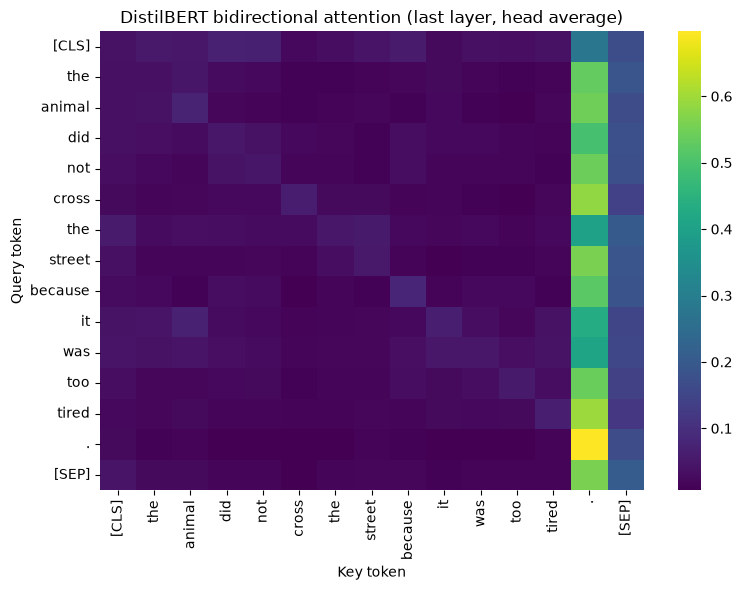

In [89]:
# Run this cell to complete the current practical step.
one = verify_tok("The animal did not cross the street because it was too tired.", return_tensors="pt").to(TORCH_DEVICE)
with torch.no_grad():
    out = verify_model(**one, output_attentions=True)
bidirectional = out.attentions[-1][0].mean(dim=0).cpu().numpy()
tok_labels = verify_tok.convert_ids_to_tokens(one["input_ids"][0])
plt.figure(figsize=(8,6)); sns.heatmap(bidirectional, xticklabels=tok_labels, yticklabels=tok_labels, cmap="viridis")
plt.title("DistilBERT bidirectional attention (last layer, head average)")
plt.xlabel("Key token"); plt.ylabel("Query token"); plt.tight_layout()
plt.savefig(PLOT_DIR/"bidirectional_attention.png", dpi=150); plt.show()

Causal attention row sums: [1. 1. 1. 1. 1. 1.]
Maximum above diagonal: 0.0


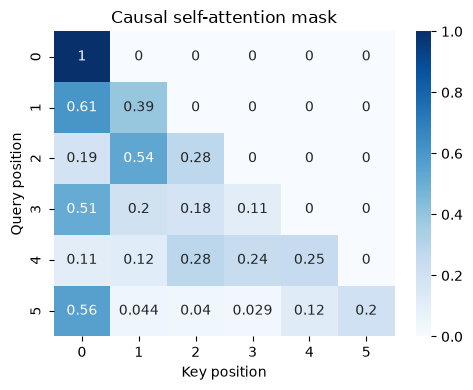

In [90]:
# Run this cell to complete the current practical step.
n = 6
causal_mask = np.triu(np.full((n,n), -np.inf), k=1)
causal_scores = np.random.default_rng(SEED).normal(size=(n,n)) + causal_mask
causal_weights = softmax_stable(causal_scores, axis=-1)
print("Causal attention row sums:", causal_weights.sum(axis=1))
print("Maximum above diagonal:", np.triu(causal_weights, k=1).max())
plt.figure(figsize=(5,4)); sns.heatmap(causal_weights, annot=True, cmap="Blues")
plt.title("Causal self-attention mask"); plt.xlabel("Key position"); plt.ylabel("Query position")
plt.tight_layout(); plt.savefig(PLOT_DIR/"causal_mask.png", dpi=150); plt.show()

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 221.74it/s]


Max above diagonal: 0.0


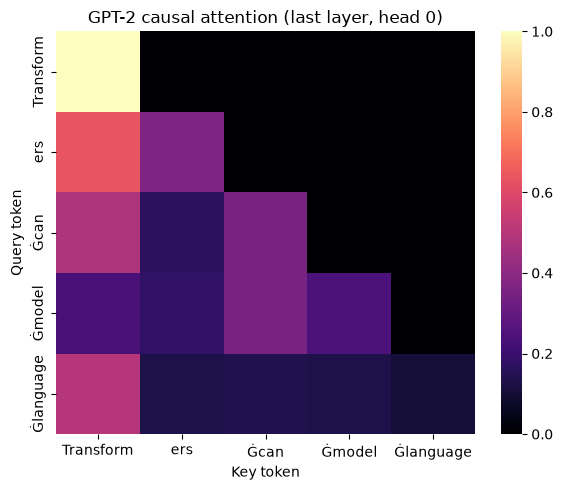

In [91]:
# Run this cell to complete the current practical step.
gpt_tok = AutoTokenizer.from_pretrained("gpt2")
gpt_model = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager").to(TORCH_DEVICE).eval()
if gpt_tok.pad_token is None:
    gpt_tok.pad_token = gpt_tok.eos_token
gpt_inputs = gpt_tok("Transformers can model language", return_tensors="pt").to(TORCH_DEVICE)
with torch.no_grad():
    gout = gpt_model(**gpt_inputs, output_attentions=True)
gpt_attn = gout.attentions[-1][0,0].cpu().numpy()
print("Max above diagonal:", np.triu(gpt_attn, k=1).max())
gtoks = gpt_tok.convert_ids_to_tokens(gpt_inputs["input_ids"][0])
plt.figure(figsize=(6,5)); sns.heatmap(gpt_attn, xticklabels=gtoks, yticklabels=gtoks, cmap="magma")
plt.title("GPT-2 causal attention (last layer, head 0)"); plt.xlabel("Key token"); plt.ylabel("Query token")
plt.tight_layout(); plt.savefig(PLOT_DIR/"gpt2_causal_attention.png", dpi=150); plt.show()

In [92]:
# Run this cell to complete the current practical step.
padded = verify_tok(["Short sentence.", "This is a substantially longer sentence that will require padding."],
                    padding=True, return_tensors="pt").to(TORCH_DEVICE)
with torch.no_grad():
    pout = verify_model(**padded, output_attentions=True)
print("Attention mask:", padded["attention_mask"].cpu().numpy())
print("Padding positions should be excluded as keys by the attention mask.")
display(pd.DataFrame([
    ["Padding mask", "Ignores padding tokens", "Batch × key positions", "Encoder and decoder batches"],
    ["Causal mask", "Prevents looking at future tokens", "Sequence × sequence triangular pattern", "Autoregressive decoder"]
], columns=["Mask", "Purpose", "Pattern/shape", "Used by"]))

Attention mask: [[1 1 1 1 1 0 0 0 0 0 0 0 0 0]
 [1 1 1 1 1 1 1 1 1 1 1 1 1 1]]
Padding positions should be excluded as keys by the attention mask.


,Mask,Purpose,Pattern/shape,Used by
0,Padding mask,Ignores padding tokens,Batch × key positions,Encoder and decoder batches
1,Causal mask,Prevents looking at future tokens,Sequence × sequence triangular pattern,Autoregressive decoder


## Task 5 — Cross-attention, decoder architecture and inference

The original decoder block applies masked self-attention, then cross-attention over encoder outputs, then a feed-forward network, each with residual connections and normalization. Encoder-only models such as DistilBERT use bidirectional self-attention; decoder-only GPT-2 uses causal self-attention and no encoder cross-attention; encoder-decoder T5 uses encoder self-attention plus decoder self-attention and cross-attention. In cross-attention, queries come from the decoder while keys and values come from the encoder output, letting each generated target token consult the source sentence.

In [93]:
# Run this cell to complete the current practical step.
t5_tok = T5Tokenizer.from_pretrained("t5-small")
t5_model = T5ForConditionalGeneration.from_pretrained(
    "t5-small", attn_implementation="eager"
).to(TORCH_DEVICE).eval()

translation_examples = [
    "The house is small.",
    "Transformers process language.",
    "I enjoy learning new ideas."
]

for sentence in translation_examples:
    prompt = "translate English to French: " + sentence
    inputs = t5_tok(prompt, return_tensors="pt", truncation=True).to(TORCH_DEVICE)
    with torch.no_grad():
        output_ids = t5_model.generate(**inputs, max_new_tokens=64)
    translation = t5_tok.decode(output_ids[0], skip_special_tokens=True)
    print(sentence, "->", translation)


Loading weights: 100%|██████████| 131/131 [00:00<00:00, 16244.98it/s]


The house is small. -> La maison est petite.
Transformers process language. -> Langue de transformation des procédés.
I enjoy learning new ideas. -> J'aime apprendre de nouvelles idées.


In [94]:
# Run this cell to complete the current practical step.
paragraph = ("Transformers are neural network architectures that use attention to combine information across a sequence. "
             "Unlike recurrent networks, they can process positions in parallel during training. Encoder models are useful "
             "for understanding tasks, decoder models generate text one token at a time, and encoder-decoder models can "
             "map an input sequence to a different output sequence. Their strengths come with trade-offs including compute "
             "cost, finite context windows, and the possibility of producing inaccurate information.")

def summarize_text(text):
    inputs = t5_tok(
        "summarize: " + text,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(TORCH_DEVICE)
    with torch.no_grad():
        output_ids = t5_model.generate(
            **inputs,
            max_new_tokens=60,
            do_sample=False
        )
    return t5_tok.decode(output_ids[0], skip_special_tokens=True)

summary = summarize_text(paragraph)
print("Input words:", len(paragraph.split()))
print("Summary words:", len(summary.split()))
print(summary)


Input words: 72
Summary words: 43
transformers are neural network architectures that use attention to combine information across a sequence. they can process positions in parallel during training. decoder models generate text one token at a time, and encoder-decoder models map an input sequence to a different output sequence


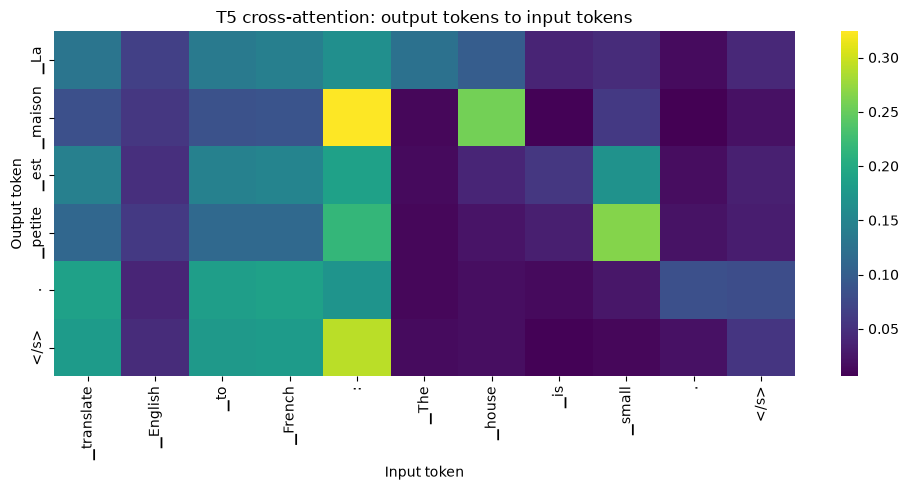

In [95]:
# Run this cell to complete the current practical step.
cross_text = "translate English to French: The house is small."
target_text = "La maison est petite."
cross_in = t5_tok(cross_text, return_tensors="pt").to(TORCH_DEVICE)
labels = t5_tok(target_text, return_tensors="pt").input_ids.to(TORCH_DEVICE)
with torch.no_grad():
    cross_out = t5_model(input_ids=cross_in["input_ids"], attention_mask=cross_in["attention_mask"],
                         labels=labels, output_attentions=True)
cross = cross_out.cross_attentions[-1][0].mean(dim=0).cpu().numpy()
src_tokens = t5_tok.convert_ids_to_tokens(cross_in["input_ids"][0])
tgt_tokens = t5_tok.convert_ids_to_tokens(labels[0])
plt.figure(figsize=(10,5)); sns.heatmap(cross, xticklabels=src_tokens, yticklabels=tgt_tokens, cmap="viridis")
plt.title("T5 cross-attention: output tokens to input tokens"); plt.xlabel("Input token"); plt.ylabel("Output token")
plt.tight_layout(); plt.savefig(PLOT_DIR/"cross_attention.png", dpi=150); plt.show()

In [96]:
# Run this cell to complete the current practical step.
prompt = "Artificial intelligence will"
input_ids = gpt_tok(prompt, return_tensors="pt").input_ids.to(TORCH_DEVICE)
manual_ids = input_ids.clone()
with torch.no_grad():
    for _ in range(20):
        logits = gpt_model(input_ids=manual_ids).logits[:, -1, :]
        next_id = torch.argmax(logits, dim=-1, keepdim=True)
        manual_ids = torch.cat([manual_ids, next_id], dim=-1)
    generated_ids = gpt_model.generate(input_ids, max_new_tokens=20, do_sample=False)
print("Manual:", gpt_tok.decode(manual_ids[0], skip_special_tokens=True))
print("generate:", gpt_tok.decode(generated_ids[0], skip_special_tokens=True))
print("Identical:", torch.equal(manual_ids, generated_ids))

Manual: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
generate: Artificial intelligence will be able to do things like search for and find people, and to do things like find out who
Identical: True


In [97]:
# Run this cell to complete the current practical step.
decode_rows = []
settings = [
    ("Greedy", dict(do_sample=False)),
    ("Beam search", dict(do_sample=False, num_beams=5, early_stopping=True)),
    ("Sampling temp=0.7 seed=42", dict(do_sample=True, temperature=0.7)),
    ("Sampling temp=1.5 seed=43", dict(do_sample=True, temperature=1.5)),
    ("Top-k=50, top-p=0.9", dict(do_sample=True, top_k=50, top_p=0.9, temperature=1.0))
]
for i, (label, kwargs) in enumerate(settings):
    torch.manual_seed(SEED + i)
    with torch.no_grad():
        out_ids = gpt_model.generate(input_ids, max_new_tokens=40, pad_token_id=gpt_tok.eos_token_id, **kwargs)
    decode_rows.append({"Strategy": label, "Output": gpt_tok.decode(out_ids[0], skip_special_tokens=True)})
display(pd.DataFrame(decode_rows))

,Strategy,Output
0,Greedy,Artificial intelligence will be able to do thi...
1,Beam search,Artificial intelligence will be the next big t...
2,Sampling temp=0.7 seed=42,Artificial intelligence will help to advance o...
3,Sampling temp=1.5 seed=43,"Artificial intelligence will evolve its ""intel..."
4,"Top-k=50, top-p=0.9",Artificial intelligence will allow you to crea...


In [98]:
# Run this cell to complete the current practical step.
def generation_time(use_cache, runs=3):
    times = []
    for _ in range(runs):
        start = time.perf_counter()
        with torch.no_grad():
            gpt_model.generate(input_ids, max_new_tokens=100, use_cache=use_cache,
                               do_sample=False, pad_token_id=gpt_tok.eos_token_id)
        times.append(time.perf_counter() - start)
    return float(np.mean(times))
# This can take a few minutes on CPU.
cache_true = generation_time(True)
cache_false = generation_time(False)
print(f"use_cache=True: {cache_true:.3f}s")
print(f"use_cache=False: {cache_false:.3f}s")
print(f"Speed-up (false/true): {cache_false/cache_true:.2f}x")

use_cache=True: 1.921s
use_cache=False: 1.896s
Speed-up (false/true): 0.99x


| Model | Family | Attention | Generate text? | Position scheme | Typical tasks |
|---|---|---|---|---|---|
| DistilBERT | Encoder-only | Bidirectional self-attention | Not as a standard text generator | Learned absolute positions | Classification, embeddings, fill-mask |
| GPT-2 | Decoder-only | Causal self-attention | Yes | Learned positions | Autocomplete and generation |
| T5-small | Encoder-decoder | Encoder self-attention, decoder causal self-attention, cross-attention | Yes | Relative position bias | Translation, summarization, text-to-text tasks |

## Task 6 — Evaluation, truncation, disadvantages and mini application

In [99]:
# Run this cell to complete the current practical step.
imdb = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=SEED).select(range(200))
reviews = [x["text"] for x in imdb]
y_true = np.array([x["label"] for x in imdb])
print("Loaded reviews:", len(reviews), "labels:", np.unique(y_true, return_counts=True))

Loaded reviews: 200 labels: (array([0, 1]), array([104,  96]))


,max_length,accuracy,precision,recall,f1,seconds
0,64,0.750,0.767442,0.687500,0.725275,0.741388
1,128,0.775,0.757576,0.781250,0.769231,0.849610
2,256,0.840,0.863636,0.791667,0.826087,1.680180
3,512,0.870,0.888889,0.833333,0.860215,3.331545


Confusion matrix at max_length=512:
 [[94 10]
 [16 80]]
              precision    recall  f1-score   support

           0       0.85      0.90      0.88       104
           1       0.89      0.83      0.86        96

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



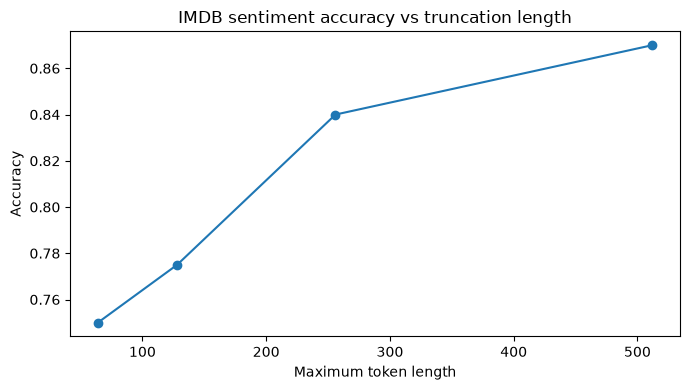

In [100]:
# Run this cell to complete the current practical step.
def evaluate_length(max_len):
    preds, scores = [], []
    start = time.perf_counter()
    for i in range(0, len(reviews), 16):
        batch_text = reviews[i:i+16]
        results = sentiment_pipe(batch_text, truncation=True, max_length=max_len, batch_size=16)
        for r in results:
            preds.append(1 if r["label"] == "POSITIVE" else 0)
            scores.append(r["score"])
    elapsed = time.perf_counter() - start
    return {
        "max_length": max_len,
        "accuracy": accuracy_score(y_true, preds),
        "precision": precision_score(y_true, preds, zero_division=0),
        "recall": recall_score(y_true, preds, zero_division=0),
        "f1": f1_score(y_true, preds, zero_division=0),
        "seconds": elapsed,
        "predictions": preds
    }
eval_results = [evaluate_length(n) for n in [64, 128, 256, 512]]
eval_df = pd.DataFrame([{k:v for k,v in r.items() if k != "predictions"} for r in eval_results])
display(eval_df)
best = eval_results[-1]
print("Confusion matrix at max_length=512:\n", confusion_matrix(y_true, best["predictions"]))
print(classification_report(y_true, best["predictions"], zero_division=0))
plt.figure(figsize=(7,4)); plt.plot(eval_df["max_length"], eval_df["accuracy"], marker="o")
plt.xlabel("Maximum token length"); plt.ylabel("Accuracy"); plt.title("IMDB sentiment accuracy vs truncation length")
plt.tight_layout(); plt.savefig(PLOT_DIR/"truncation_accuracy.png", dpi=150); plt.show()

In [101]:
# Run this cell to complete the current practical step.
raw_lens = [len(tok(r, truncation=False)["input_ids"]) for r in reviews]
print("Reviews exceeding 512 tokens:", sum(n > 512 for n in raw_lens))
print("Maximum review token length:", max(raw_lens))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (632 > 512). Running this sequence through the model will result in indexing errors


Reviews exceeding 512 tokens: 18
Maximum review token length: 1453


,tokens,mean_seconds
0,32,0.007629
1,64,0.007551
2,128,0.008067
3,256,0.009450
4,512,0.019356


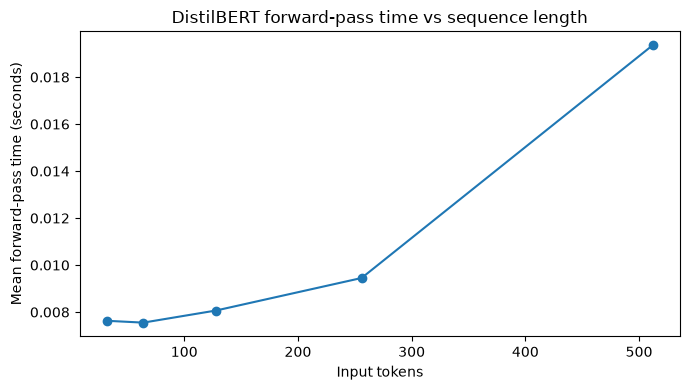

In [102]:
# Run this cell to complete the current practical step.
timings = []
probe = "Attention compares tokens with other tokens. " * 120
for length in [32, 64, 128, 256, 512]:
    sample = verify_tok(probe, return_tensors="pt", truncation=True, max_length=length).to(TORCH_DEVICE)
    with torch.no_grad():
        verify_model(**sample)  # warm-up
        runs = []
        for _ in range(10):
            start = time.perf_counter()
            verify_model(**sample)
            if TORCH_DEVICE.type == "cuda":
                torch.cuda.synchronize()
            runs.append(time.perf_counter() - start)
    timings.append({"tokens": length, "mean_seconds": np.mean(runs)})
timing_df = pd.DataFrame(timings)
display(timing_df)
plt.figure(figsize=(7,4)); plt.plot(timing_df["tokens"], timing_df["mean_seconds"], marker="o")
plt.xlabel("Input tokens"); plt.ylabel("Mean forward-pass time (seconds)"); plt.title("DistilBERT forward-pass time vs sequence length")
plt.tight_layout(); plt.savefig(PLOT_DIR/"time_vs_length.png", dpi=150); plt.show()

In [103]:
# Run this cell to complete the current practical step.
fact_prompts = [
    "The capital of Australia is",
    "The author of the novel Pride and Prejudice is",
    "The inventor of the telephone was"
]
for fact_prompt in fact_prompts:
    fact_ids = gpt_tok(fact_prompt, return_tensors="pt").input_ids.to(TORCH_DEVICE)
    with torch.no_grad():
        generated = gpt_model.generate(fact_ids, max_new_tokens=30, do_sample=False, pad_token_id=gpt_tok.eos_token_id)
    print("\nPrompt:", fact_prompt)
    print("Output:", gpt_tok.decode(generated[0], skip_special_tokens=True))
print("Review each output manually and mark Correct / Partly correct / Wrong in your report; model output is not a reliable source of facts.")


Prompt: The capital of Australia is
Output: The capital of Australia is the world's largest producer of coal, and the country's largest coal-fired power station.

The coal industry is also the world's largest

Prompt: The author of the novel Pride and Prejudice is
Output: The author of the novel Pride and Prejudice is a former member of the National Security Council.

The author of the novel is a former member of the National Security Council.

The author

Prompt: The inventor of the telephone was
Output: The inventor of the telephone was a man named John D. Rockefeller. He was a man who had been a member of the Rockefeller family for many years. He was a man who
Review each output manually and mark Correct / Partly correct / Wrong in your report; model output is not a reliable source of facts.


In [104]:
# Run this cell to complete the current practical step.
def text_toolkit(text):
    if not isinstance(text, str) or not text.strip():
        return {
            "sentiment_label": "N/A",
            "sentiment_score": np.nan,
            "summary": "Please provide non-empty text.",
            "french_translation": "No translation available.",
            "note": "Empty input."
        }

    clean = text.strip()
    clipped = clean[:12000]
    sentiment = sentiment_pipe(clipped, truncation=True, max_length=512)[0]

    # Summarize with T5 directly; Transformers v5 removed the summarization pipeline.
    summary_inputs = t5_tok(
        "summarize: " + clipped,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(TORCH_DEVICE)
    with torch.no_grad():
        summary_ids = t5_model.generate(
            **summary_inputs,
            max_new_tokens=60,
            do_sample=False
        )
    summary_result = t5_tok.decode(summary_ids[0], skip_special_tokens=True)

    # Translate the summary with T5 directly; no translation pipeline required.
    trans_input = "translate English to French: " + summary_result
    trans_ids = t5_tok(
        trans_input,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(TORCH_DEVICE)
    with torch.no_grad():
        trans_out = t5_model.generate(**trans_ids, max_new_tokens=100, do_sample=False)
    french = t5_tok.decode(trans_out[0], skip_special_tokens=True)

    message = "Input clipped to 12,000 characters." if len(text) > 12000 else ""
    return {
        "sentiment_label": sentiment["label"],
        "sentiment_score": round(float(sentiment["score"]), 4),
        "summary": summary_result,
        "french_translation": french,
        "note": message
    }


In [105]:
# Run this cell to complete the current practical step.
passages = [
    "I loved the product. It arrived quickly, feels durable, and works exactly as described. I would recommend it.",
    "The city council announced a new public transport plan that will add electric buses, improve service frequency, and upgrade several stations over the next two years.",
    "I am studying deep learning and want to understand how attention helps a model connect information across a sentence."
]
toolkit_df = pd.DataFrame([{"Passage": p, **text_toolkit(p)} for p in passages])
display(toolkit_df)
print("Empty-input check:", text_toolkit("   "))

,Passage,sentiment_label,sentiment_score,summary,french_translation,note
0,"I loved the product. It arrived quickly, feels...",POSITIVE,0.9998,"the product arrived quickly, feels durable, an...","Le produit est arrivé rapidement, se sent dura...",
1,The city council announced a new public transp...,POSITIVE,0.9575,the city council announced a new public transp...,Le conseil municipal a annoncé un nouveau plan...,
2,I am studying deep learning and want to unders...,POSITIVE,0.9819,deep learning is a model that connects informa...,L'apprentissage approfondi est un modèle qui r...,


Empty-input check: {'sentiment_label': 'N/A', 'sentiment_score': nan, 'summary': 'Please provide non-empty text.', 'french_translation': 'No translation available.', 'note': 'Empty input.'}


### What I learned about Transformers
- I understand best: self-attention, where queries and keys determine how values are mixed.
- I still need to investigate: why specific learned attention patterns emerge across different tasks.
- Theory check: the manually computed causal mask prevented attention to future tokens; the real GPT-2 attention matrix should have near-zero values above its diagonal.
- Practical disadvantages measured here: the accuracy/time trade-off across truncation lengths, and the forward-pass timing trend as sequence length grows. Report the actual values from the tables rather than inventing a general result.
- An application I would build: a review-analysis helper that classifies sentiment and summarizes feedback; an encoder is suitable for sentiment classification and an encoder-decoder model for summaries/translations.